In [1]:
import sys
sys.path.append("..")
from src.metrics import mann_whitney_with_effect_size
from src.viz import plot_group_boxplot
from src.db import append_note
import pandas as pd

In [2]:
df_analysis = pd.read_csv("../data/processed/analysis_base.csv")

{'n1': 47, 'n2': 86, 'median1': np.float64(643.0), 'median2': np.float64(990.0), 'u_stat': np.float64(1480.5), 'p_value': np.float64(0.01102879890824362), 'effect_size_r': np.float64(0.2674)}


Đã lưu: ../reports/figures\h5_interest_score_boxplot.png


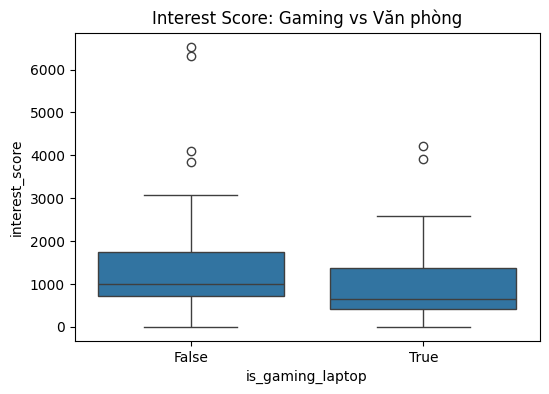

,mean,median,count
is_gaming_laptop,,,
False,2024.616279,2025.0,86
True,2024.446809,2024.0,47


In [3]:
### H5: interest_score gaming vs văn phòng
result_h5 = mann_whitney_with_effect_size(
    df_analysis.loc[df_analysis["is_gaming_laptop"] == True, "interest_score"],
    df_analysis.loc[df_analysis["is_gaming_laptop"] != True, "interest_score"],
)
print(result_h5)
plot_group_boxplot(df_analysis, "is_gaming_laptop", "interest_score",
                    "Interest Score: Gaming vs Văn phòng", "h5_interest_score_boxplot.png")

### Kiểm soát biến nhiễu: is_gaming_laptop có tương quan với year_introduce không?
confound_check = df_analysis.groupby("is_gaming_laptop")["year_introduce"].agg(["mean", "median", "count"])
display(confound_check)


In [4]:
note = f"""
## [Giai đoạn 3 - Trục 2] H5 — Kết quả

Mann-Whitney interest_score (Gaming vs Văn phòng): {result_h5}

Kiểm tra biến nhiễu year_introduce theo phân khúc:
{confound_check.to_markdown()}

**Diễn giải:** nếu 2 nhóm lệch nhau đáng kể về year_introduce, khác biệt interest_score
có thể do laptop mới ra mắt được xem nhiều hơn (recency bias) chứ không thuần do phân khúc gaming.
Cần nêu rõ giới hạn này khi trình bày insight, correlation != causation.
"""
append_note(note)

In [5]:
### [Giai đoạn 3 - C, đính chính] Làm rõ chiều kết quả H5 — NGƯỢC với giả thuyết ban đầu
h5_direction_note = f"""
## [Giai đoạn 3 - Trục 2] Đính chính chiều kết quả H5

H5 gốc giả thuyết: "laptop gaming nhận nhiều interest_score hơn laptop văn phòng".
Kết quả thực tế: median interest_score của gaming ({result_h5['median1']}) THẤP HƠN
văn phòng ({result_h5['median2']}), khác biệt có ý nghĩa thống kê (p={result_h5['p_value']:.4f},
effect size r={result_h5['effect_size_r']}).

**Kết luận: bác bỏ giả thuyết H5 gốc theo đúng chiều đã đề ra — chiều thực tế NGƯỢC LẠI.**
Đây vẫn là một insight có giá trị (người dùng thực ra quan tâm/so sánh laptop văn phòng nhiều
hơn gaming), nhưng cần trình bày đúng bản chất ở Giai đoạn 4/6, không diễn đạt nhầm thành
"xác nhận gaming được quan tâm hơn".
"""
append_note(h5_direction_note)